In [1]:
# Data packages
import pandas as pd
import numpy as np
import shap
from imblearn.over_sampling import SMOTE
from sklearn.conftest import pytest_generate_tests
from sklearn.ensemble import RandomForestClassifier

# ML / Classification packages
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbalancedPipeline

# Visualization packages
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import gradio as gr



/home/germs/PycharmProjects/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
default_risk = pd.read_csv(r"Data/Loan_Default.csv")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)

default_risk.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,116500,NaN,NaN,NaN,360.0,not_neg,not_int,not_lpsm,118000.0,sb,pr,home,1U,1740.0,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,206500,NaN,NaN,NaN,360.0,not_neg,not_int,lpsm,NaN,sb,pr,home,1U,4980.0,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,406500,4.56,0.2000,595.0,360.0,neg_amm,not_int,not_lpsm,508000.0,sb,pr,home,1U,9480.0,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,456500,4.25,0.6810,NaN,360.0,not_neg,not_int,not_lpsm,658000.0,sb,pr,home,1U,11880.0,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,696500,4.00,0.3042,0.0,360.0,not_neg,not_int,not_lpsm,758000.0,sb,pr,home,1U,10440.0,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [3]:
default_risk.describe(include='all')

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
count,148670.000000,148670.0,145326,148670,147762,148670,148536,148670,148670,148670,1.486700e+05,112231.000000,112031.000000,109028.000000,148629.000000,148549,148670,148670,1.335720e+05,148670,148670,148670,148670,139520.000000,148670,148670.000000,148670,148470,148470,133572.000000,148670,148670,148670.000000,124549.000000
unique,NaN,NaN,2,4,2,3,4,2,2,2,NaN,NaN,NaN,NaN,NaN,2,2,2,NaN,2,3,2,4,NaN,4,NaN,2,7,2,NaN,4,2,NaN,NaN
top,NaN,NaN,cf,Male,nopre,type1,p3,l1,nopc,nob/c,NaN,NaN,NaN,NaN,NaN,not_neg,not_int,not_lpsm,NaN,sb,pr,home,1U,NaN,CIB,NaN,CIB,45-54,to_inst,NaN,North,direct,NaN,NaN
freq,NaN,NaN,135348,42346,124621,113173,55934,142344,148114,127908,NaN,NaN,NaN,NaN,NaN,133420,141560,145286,NaN,148637,138201,148637,146480,NaN,48152,NaN,74392,34720,95814,NaN,74722,148637,NaN,NaN
mean,99224.500000,2019.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.311177e+05,4.045476,0.441656,3224.996127,335.136582,NaN,NaN,NaN,4.978935e+05,NaN,NaN,NaN,NaN,6957.338876,NaN,699.789103,NaN,NaN,NaN,72.746457,NaN,NaN,0.246445,37.732932
std,42917.476598,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.839093e+05,0.561391,0.513043,3251.121510,58.409084,NaN,NaN,NaN,3.599353e+05,NaN,NaN,NaN,NaN,6496.586382,NaN,115.875857,NaN,NaN,NaN,39.967603,NaN,NaN,0.430942,10.545435
min,24890.000000,2019.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.650000e+04,0.000000,-3.638000,0.000000,96.000000,NaN,NaN,NaN,8.000000e+03,NaN,NaN,NaN,NaN,0.000000,NaN,500.000000,NaN,NaN,NaN,0.967478,NaN,NaN,0.000000,5.000000
25%,62057.250000,2019.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.965000e+05,3.625000,0.076000,581.490000,360.000000,NaN,NaN,NaN,2.680000e+05,NaN,NaN,NaN,NaN,3720.000000,NaN,599.000000,NaN,NaN,NaN,60.474860,NaN,NaN,0.000000,31.000000
50%,99224.500000,2019.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.965000e+05,3.990000,0.390400,2596.450000,360.000000,NaN,NaN,NaN,4.180000e+05,NaN,NaN,NaN,NaN,5760.000000,NaN,699.000000,NaN,NaN,NaN,75.135870,NaN,NaN,0.000000,39.000000
75%,136391.750000,2019.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.365000e+05,4.375000,0.775400,4812.500000,360.000000,NaN,NaN,NaN,6.280000e+05,NaN,NaN,NaN,NaN,8520.000000,NaN,800.000000,NaN,NaN,NaN,86.184211,NaN,NaN,0.000000,45.000000


# Data Cleaning and Validation

The Equal Credit Opportunity Act prohibits discrimination in lending based on certain protected characteristics such as race, gender, religion, and age.

Columns related to these protected characteristics should not be used in the training model.

#### Gender

Our dataset includes a gender column that serves a dual purpose: indicating whether this is a joint application or not. The amount of borrowers can have a measurable impact on credit worthiness and the probability of default. Therefore, we will want to extract instances where a loan is marked as joint into a separate column and then delete the 'Gender' column altogether.


In [4]:
# Create a copy for training
default_risk_train = default_risk.copy()

# Extract joint application column
default_risk_train['joint_application'] = default_risk_train['Gender'].apply(lambda x: 1 if x == 'Joint' else 0)

# Drop protected characteristics
default_risk_train = default_risk_train.drop(columns=['Gender', 'age'])

# Drop identifier columns
default_risk_train = default_risk_train.drop(columns=['ID'])



# Determined some columns are causing leakage
# Drop leakage columns before training
leakage_columns = [
    "rate_of_interest",
    "Interest_rate_spread",
    "Upfront_charges"
]

default_risk_train = default_risk_train.drop(columns=leakage_columns)



# Drop columns with constant or near-constant values
constant_columns = [col for col in default_risk_train.columns if default_risk_train[col].nunique() == 1]
quasi_constant_columns = [col for col in default_risk_train.columns if default_risk_train[col].value_counts(normalize=True, dropna=False).iloc[0] > 0.96 and col not in constant_columns]

print("Columns with constant values to drop from training model:", constant_columns)
print("Columns with near-constant values (>96% single category):", quasi_constant_columns)

default_risk_train = default_risk_train.drop(columns=constant_columns + quasi_constant_columns)
default_risk_train.head()

Columns with constant values to drop from training model: ['year']
Columns with near-constant values (>96% single category): ['open_credit', 'lump_sum_payment', 'construction_type', 'Secured_by', 'total_units', 'Security_Type']


,loan_limit,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,business_or_commercial,loan_amount,term,Neg_ammortization,interest_only,property_value,occupancy_type,income,credit_type,Credit_Score,co-applicant_credit_type,submission_of_application,LTV,Region,Status,dtir1,joint_application
0,cf,nopre,type1,p1,l1,nob/c,116500,360.0,not_neg,not_int,118000.0,pr,1740.0,EXP,758,CIB,to_inst,98.728814,south,1,45.0,0
1,cf,nopre,type2,p1,l1,b/c,206500,360.0,not_neg,not_int,NaN,pr,4980.0,EQUI,552,EXP,to_inst,NaN,North,1,NaN,0
2,cf,pre,type1,p1,l1,nob/c,406500,360.0,neg_amm,not_int,508000.0,pr,9480.0,EXP,834,CIB,to_inst,80.019685,south,0,46.0,0
3,cf,nopre,type1,p4,l1,nob/c,456500,360.0,not_neg,not_int,658000.0,pr,11880.0,EXP,587,CIB,not_inst,69.376900,North,0,42.0,0
4,cf,pre,type1,p1,l1,nob/c,696500,360.0,not_neg,not_int,758000.0,pr,10440.0,CRIF,602,EXP,not_inst,91.886544,North,0,39.0,1


#### Imputing Missing Values, One-Hot Encoding and SMOTE

One-Hot Encoding is a technique used to convert categorical variables into a format that can be provided to machine learning algorithms to improve prediction accuracy. This is necessary because most machine learning algorithms work best with numerical data. One-Hot Encoding creates new binary columns for each category in a categorical variable, with a value of 1 indicating the presence of the category and 0 indicating its absence.

Before this, we need to handle missing values in the dataset. Missing values can cause issues in machine learning models, so it's important to address them before proceeding with data preprocessing. We will use the SimpleImputer from Scikit-Learn to fill in missing values with the median for numerical columns and "Unknown" categorical columns.

This will be implemented here using the Scikit-Learn Pipeline, which allows for a sequence of data processing steps to be chained together. This will help to streamline the data preprocessing pipeline and make it easier to manage and maintain.

In [5]:
# Split X and Y for SMOTE
y = default_risk_train['Status']
x = default_risk_train.drop(columns=['Status'])

# Split into training and test sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


# Select categorical columns
categorical_columns = x_train.select_dtypes(include=['object', 'str']).columns
numerical_columns = x_train.select_dtypes(include=['number']).columns

# Define the categorical pipeline to impute NaNs with 'Unknown' and then pipe to One-Hot Encode
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

# Define the numerical pipeline to impute NaNs with the median
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Combine pipelines into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
    ('cat', cat_pipeline, categorical_columns),
    ('num', num_pipeline, numerical_columns)
    ],
    remainder='passthrough'
)


# Configure transformer to output a Pandas DataFrame
preprocessor.set_output(transform='pandas')

# Fit preprocessing data on training set only, transforming both training and test sets
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

# # Fix and transform data
# default_risk_train = preprocessor.fit_transform(default_risk_train)

# # Convert to binary
# encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
#
# encoded_data = encoder.fit_transform(default_risk_train[categorical_columns])
#
# encoded_default_risk_train = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(categorical_columns))
#
# default_risk_train = pd.concat([default_risk_train.drop(columns=categorical_columns), encoded_default_risk_train], axis=1)

print("Imputation and One-Hot Encoding complete:")
display(default_risk_train.head())

Imputation and One-Hot Encoding complete:


,loan_limit,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,business_or_commercial,loan_amount,term,Neg_ammortization,interest_only,property_value,occupancy_type,income,credit_type,Credit_Score,co-applicant_credit_type,submission_of_application,LTV,Region,Status,dtir1,joint_application
0,cf,nopre,type1,p1,l1,nob/c,116500,360.0,not_neg,not_int,118000.0,pr,1740.0,EXP,758,CIB,to_inst,98.728814,south,1,45.0,0
1,cf,nopre,type2,p1,l1,b/c,206500,360.0,not_neg,not_int,NaN,pr,4980.0,EQUI,552,EXP,to_inst,NaN,North,1,NaN,0
2,cf,pre,type1,p1,l1,nob/c,406500,360.0,neg_amm,not_int,508000.0,pr,9480.0,EXP,834,CIB,to_inst,80.019685,south,0,46.0,0
3,cf,nopre,type1,p4,l1,nob/c,456500,360.0,not_neg,not_int,658000.0,pr,11880.0,EXP,587,CIB,not_inst,69.376900,North,0,42.0,0
4,cf,pre,type1,p1,l1,nob/c,696500,360.0,not_neg,not_int,758000.0,pr,10440.0,CRIF,602,EXP,not_inst,91.886544,North,0,39.0,1


In [6]:
default_risk_train.isna().sum().sort_values(ascending=False).head(20)

dtir1                        24121
property_value               15098
LTV                          15098
income                        9150
loan_limit                    3344
approv_in_adv                  908
submission_of_application      200
loan_purpose                   134
Neg_ammortization              121
term                            41
business_or_commercial           0
Credit_Worthiness                0
loan_type                        0
interest_only                    0
credit_type                      0
occupancy_type                   0
loan_amount                      0
co-applicant_credit_type         0
Credit_Score                     0
Region                           0
dtype: int64

#### SMOTE & Model

In [7]:
# Chain preprocessing and SMOTE into model
final_pipeline = ImbalancedPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

final_pipeline.fit(x_train, y_train)

y_pred = final_pipeline.predict(x_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.98      0.93     22494
           1       0.92      0.59      0.72      7240

    accuracy                           0.89     29734
   macro avg       0.90      0.79      0.82     29734
weighted avg       0.89      0.89      0.88     29734

[[22119   375]
 [ 2992  4248]]
Accuracy: 0.8867626286406134


In [11]:
# Test results
# for col in ["rate_of_interest", "Interest_rate_spread", "Upfront_charges"]:
#     print(col)
#     print(default_risk_train.groupby("Status")[col].apply(lambda s: s.isna().mean()))
#     print()

missing_by_status = default_risk_train.groupby("Status").apply(
    lambda df: df.isna().mean()
).T

missing_by_status["difference"] = (
        missing_by_status[1] - missing_by_status[0]
).abs()

missing_by_status.sort_values("difference", ascending=False).head(15)

Status,0,1,difference
property_value,0.000018,0.412020,0.412002
LTV,0.000018,0.412020,0.412002
dtir1,0.069722,0.445154,0.375432
income,0.070614,0.033816,0.036798
submission_of_application,0.000000,0.005459,0.005459
loan_limit,0.021985,0.024045,0.002060
approv_in_adv,0.005954,0.006578,0.000624
term,0.000232,0.000409,0.000177
Neg_ammortization,0.000794,0.000873,0.000079
loan_purpose,0.000884,0.000955,0.000072


#### Applying SHAP

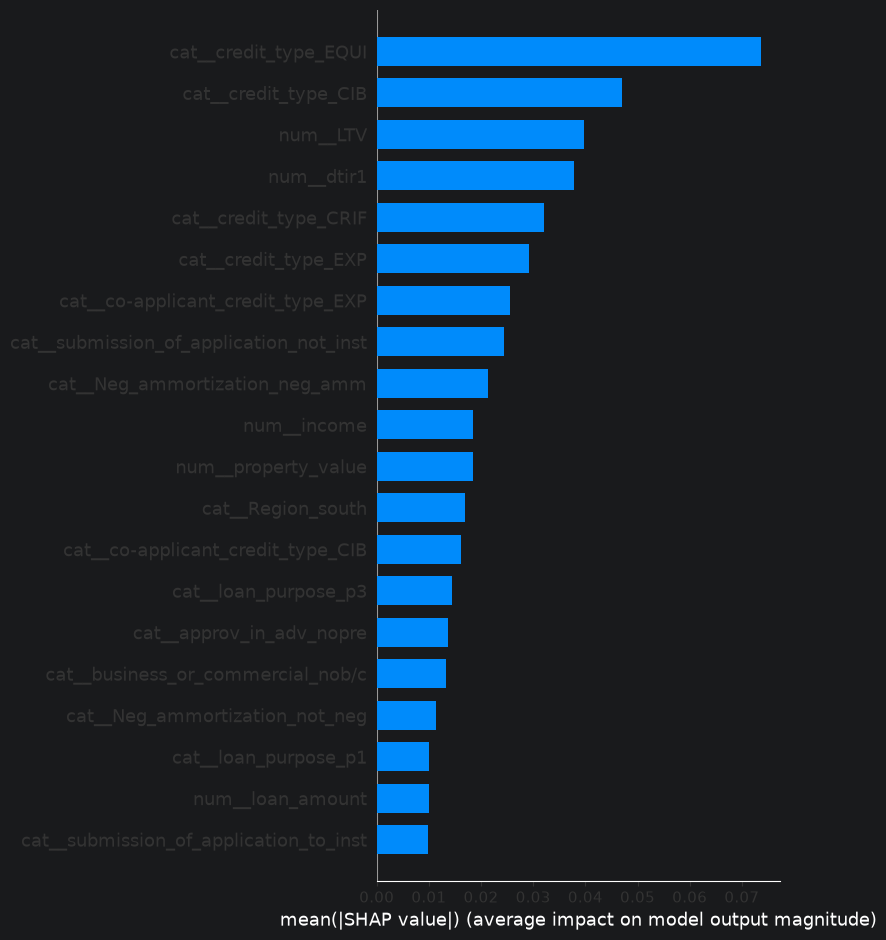

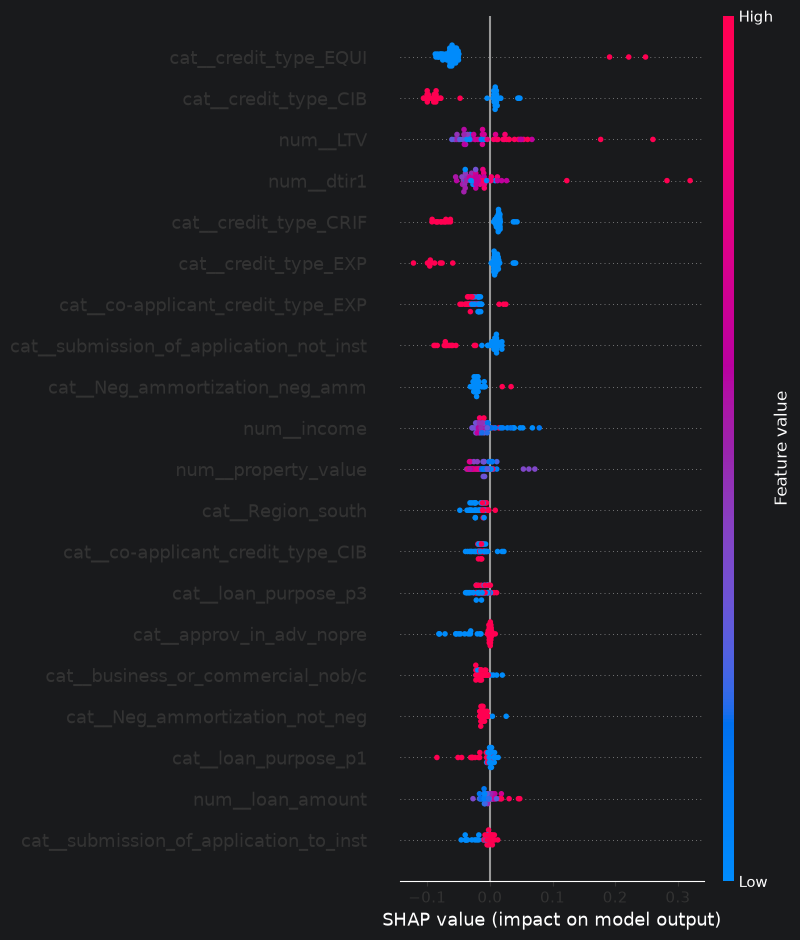

In [10]:
# Extract trained model and fitted preprocessor
model = final_pipeline.named_steps["classifier"]
fitted_preprocessor = final_pipeline.named_steps["preprocessor"]

# Transform test data into same format as our RF model
x_test_transformed = fitted_preprocessor.transform(x_test)

# Get transformed feature names
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# Sample for SHAP speed
sample_size = min(50, len(x_test_transformed))
X_shap = x_test_transformed.sample(
    n=sample_size,
    random_state=42
)

# Create SHAP explainer for Random Forest
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Select SHAP values for positive class
if isinstance(shap_values, list):
    shap_values_class_1 = shap_values[1]
else:
    shap_values_class_1 = shap_values[:, :, 1]

# Global feature importance
shap.summary_plot(
    shap_values_class_1,
    X_shap,
    plot_type="bar"
)

# Detailed global explanation
shap.summary_plot(
    shap_values_class_1,
    X_shap
)

#### UI Using Gradio

Here we take our model and create a Gradio interface to interact with it. We also display a SHAP waterfall plot for the first instance.

In [12]:
def predict_default(*args):
    columns = [
        "loan_limit", "approv_in_adv", "loan_type", "loan_purpose",
        "Credit_Worthiness", "business_or_commercial", "loan_amount",
        "term", "Neg_ammortization", "interest_only", "property_value",
        "occupancy_type", "income", "credit_type", "Credit_Score",
        "co-applicant_credit_type", "submission_of_application", "LTV",
        "Region", "dtir1", "joint_application"
    ]

    # Create a dataframe from user inputs
    user_inputs = pd.DataFrame([args], columns=columns)

    # Use our trained imbalanced pipeline to make predictions and probability
    prediction = final_pipeline.predict(user_inputs)[0]



    # FINISH
    # probability = final_pipeline.predict_proba(user_inputs)[0]





    # Return a human-readable result based on the Status variable
    result_text = "High Risk of Default (1)" if prediction == 1 else "Low Risk of Default (0)"

    # Isolate the preprocessor and the Random Forest model from your pipeline
    fitted_prediction_preprocessor = final_pipeline.named_steps["preprocessor"]
    rf_model = final_pipeline.named_steps["classifier"]

    # Transform Gradio input into numeric format for our RF model
    numeric_inputs = fitted_prediction_preprocessor.transform(user_inputs)

    # Generate SHAP values using TreeExplainer
    shap_explainer = shap.TreeExplainer(rf_model)
    explanation = shap_explainer(numeric_inputs)

    # Visualize SHAP values
    # shap.summary_plot(shap_values, numeric_inputs, feature_names=preprocessor.get_feature_names_out())

    # Create a Matplotlib figure for Gradio
    plt.close("all")
    fig = plt.gcf()

    # Create a waterfall plot for the first instance
    shap.plots.waterfall(explanation[0, :, 1], show=False)

    plt.tight_layout()

    # Return both the text result and the Matplotlib figure
    return result_text, fig

# Create the interface
# Define inputs matching our feature data types and categories
inputs = [
    gr.Dropdown(choices=["cf", "nc"], label="Loan Limit"),
    gr.Dropdown(choices=["nopre", "pre"], label="Approved in Advance"),
    gr.Dropdown(choices=["type1", "type2", "type3"], label="Loan Type"),
    gr.Dropdown(choices=["p1", "p2", "p3", "p4"], label="Loan Purpose"),
    gr.Dropdown(choices=["l1", "l2"], label="Credit Worthiness"),
    gr.Dropdown(choices=["nob/c", "b/c"], label="Business or Commercial"),
    gr.Number(label="Loan Amount", value = 500000),
    gr.Number(label="Term (Months)", value=360.0),
    gr.Dropdown(choices=["not_neg", "neg_amm"], label="Negative Amortization"),
    gr.Dropdown(choices=["not_int", "int_only"], label="Interest Only"),
    gr.Number(label="Property Value", value = 480000),
    gr.Dropdown(choices=["pr", "sr", "ir"], label="Occupancy Type"),
    gr.Number(label="Income", value = 220000),
    gr.Dropdown(choices=["EXP", "EQUI", "CRIF", "CIB"], label="Credit Type"),
    gr.Number(label="Credit Score", value = 735),
    gr.Dropdown(choices=["CIB", "EXP", "CRIF", "EQUI"], label="Co-applicant Credit Type"),
    gr.Dropdown(choices=["to_inst", "not_inst"], label="Submission of Application"),
    gr.Number(label="LTV (Loan-to-Value)", value = 104),
    gr.Dropdown(choices=["North", "south", "central", "Norteast"], label="Region"),
    gr.Number(label="DTIR1 (Debt-to-Income Ratio)", value = 65),
    gr.Radio(choices=[0, 1], value = 0, label="Joint Application (0=No, 1=Yes)")
]

output = [
    gr.Textbox(label="Default Risk Prediction"),
    gr.Plot(label="SHAP Waterfall Plot")
]

# Create and launch the app
app = gr.Interface(
    fn=predict_default,
    inputs=inputs,
    outputs=output,
    title="Loan Default Risk Predictor",
    description="Enter loan and applicant details to predict the likelihood of default."
)

app.launch()


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
